# 349. Seedless local alignment on ice-binding proteins of separate origins, Swiss-Prot 2026_03

No kmerseek in this notebook. Every query is aligned to every target with Smith-Waterman
local alignment and affine gaps (Biopython 1.88 `PairwiseAligner`, mode `local`). No k-mer
step decides which pairs get aligned.

**Question.** Can a sensitive linear sequence comparison tell ice-binding proteins (IBPs) that
evolved separately apart from realistic control proteins? Does reducing the 20 amino acids to
kmerseek's hydrophobic/polar alphabet (`hp_lehninger2`) or to Dayhoff's six classes help or hurt?

**Why now.** Notebook 295 ([PR 141](https://github.com/seanome/2024-kmerseek-analysis/pull/141))
found that no kmerseek setting reached IBPs of other lineages, and notebook 298
([PR 175](https://github.com/seanome/2024-kmerseek-analysis/pull/175)) found the same for linked
word pairs on two held-out fish lineages (AFGP and type III). Those results are about the search
settings tried. Before building new seeds, this asks whether any useful sequence signal exists
for a seed to find.

**What this decides.** Which of four outcomes holds, checked in this order:

1. A reduced alphabet separates: reduced alignment works, so kmerseek's retrieval step may be the
   bottleneck, and a better seed is worth building.
2. Only the 20 amino acids separate: signal exists, but the reduction loses it.
3. No setting separates on the whole set, but a subgroup declared before the run does: only that
   subgroup is worth a targeted seed. This is not a confirmation of the broad claim.
4. Nothing separates: no linear scoring method tested here separates IBPs of separate origins from
   controls. That does not show every sequence classifier must fail.

**Decision rule.** In `scripts/ice_binding_sw_config.toml`, committed in
[0114097a](https://github.com/seanome/2024-kmerseek-analysis/commit/0114097a) together with
the development-split selection and before any evaluation-split alignment was scored. An
alignment setting separates when, on the evaluation split, all three hold:

* pooled recall of other-origin IBPs at a 1% false-positive rate is at least 0.25 (higher is
  better; 0 means none found before 1% of control pairs);
* that recall beats the best alignment-free baseline by at least 0.10;
* the area under the ROC curve (AUC) of real other-origin IBPs against shuffled copies of the same
  proteins, for the same query, is at least 0.75 (0.5 means a shuffle scores as well as the real
  protein, so order adds nothing).

**Data.** Query and target proteins all come from one panel built here: the 59 IBPs of reviewed
Swiss-Prot 2026_03 collected for notebook 295
([`data/convergence_afp/truth_set.tsv`](https://github.com/seanome/2024-kmerseek-analysis/blob/convergence-afp/data/convergence_afp/truth_set.tsv),
copied unchanged from branch `convergence-afp` at 7b1704f9), and control proteins drawn from
Swiss-Prot 2026_03 (`uniprot_sprot.2026_03.fasta.gz`, MD5 `bc9d398533e6df582b563c6c03093bd0`) and
UniProt REST queries cached in `data/ice_binding_sw/raw/`. Everything is made by

```bash
/Users/olga/anaconda3/envs/2025-kmerseek-analysis/bin/python3 scripts/ice_binding_sw_benchmark.py all
```

which runs on a laptop CPU in about two minutes. This notebook reads its tables in
`data/ice_binding_sw/` and draws them.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(70)

DATA = Path("../data/ice_binding_sw")
FIG = Path("../figures")


def read(name: str) -> pl.DataFrame:
    return pl.read_csv(DATA / name, separator="\t", infer_schema_length=10_000)


manifest = read("manifest.tsv")
selection = read("selection.tsv")
SELECTED = selection["setting"].to_list()
REFERENCE = "protein20_B62_g11e1"
# One colour per alignment alphabet, kept in every figure. Baselines are grey.
ALPHABET_COLOUR = {
    "protein20": pf.OKABE_ITO["blue"],
    "hp_lehninger2": pf.OKABE_ITO["vermillion"],
    "dayhoff6": pf.OKABE_ITO["bluish_green"],
}
BASELINE_LABEL = {
    "baseline_length": "length only",
    "baseline_composition20": "20-residue composition",
    "baseline_composition_hp_lehninger2": "H/P composition",
    "baseline_composition_dayhoff6": "Dayhoff composition",
    "baseline_distinct_3mer_fraction": "repetitiveness (distinct 3-mers)",
    "baseline_target_ala_thr_fraction": "target Ala+Thr fraction (ignores query)",
}


CATEGORY_LABEL = {
    "matched_background": "Swiss-Prot, matched length and composition",
    "hard_ala_rich": "Swiss-Prot, most alanine-rich",
    "hard_ala_thr_rich": "Swiss-Prot, most alanine+threonine-rich",
    "hard_cys_rich": "Swiss-Prot, most cysteine-rich",
    "hard_low_distinct_3mer": "Swiss-Prot, most repetitive",
    "hard_secreted": "secreted (UniProt keyword)",
    "hard_homolog_c_type_lectin": "C-type lectin domain (type II AFP fold)",
    "hard_homolog_sialic_acid_synthase": "sialic acid synthase (type III AFP homolog)",
    "hard_homolog_apolipoprotein_a1_a4_e": "apolipoprotein A1/A4/E (type IV AFP family)",
}


def alphabet_of(setting: str) -> str:
    return setting.split("_B")[0]


def method_label(setting: str) -> str:
    if setting in BASELINE_LABEL:
        return BASELINE_LABEL[setting]
    alph, rest = setting.split("_B")
    matrix, gaps = rest.split("_g")
    go, ge = gaps.split("e")
    source = f"BLOSUM{matrix}" if alph == "protein20" else f"BLOSUM{matrix} collapsed"
    return f"Smith-Waterman {alph}, {source}, gap {go}/{ge}"


def method_colour(setting: str) -> str:
    return (
        pf.GREY
        if setting.startswith("baseline_")
        else ALPHABET_COLOUR[alphabet_of(setting)]
    )


print("selected settings:", SELECTED)
print(json.loads((DATA / "eval_guard.json").read_text()))

selected settings: ['dayhoff6_B45_g6e1', 'hp_lehninger2_B45_g4e1', 'protein20_B62_g11e1']
{'selection_md5': '6748e6a91fe57845d273f9eac16d62a1', 'config_md5': 'ecb8af4b5cd56c88adefcb089a88b5a5', 'settings': ['protein20_B62_g11e1', 'hp_lehninger2_B45_g4e1', 'dayhoff6_B45_g6e1'], 'written_at': '2026-10-19T14:26:22'}


## 1. The sequence manifest: origins, evidence and splits

Each IBP gets an origin from `data/ice_binding_sw/origins.tsv`, a table of rules (UniProt family,
taxonomic family, name) with the paper behind each origin. Species are not origins: the DUF3494
family spans bacteria and fungi but is one origin spread by horizontal gene transfer (Vance et al.
2019, [doi:10.1111/febs.14764](https://doi.org/10.1111/febs.14764)), and type II AFPs of three
fish species are one lectin-like origin spread by lateral transfer (Graham et al. 2008,
[doi:10.1371/journal.pone.0002616](https://doi.org/10.1371/journal.pone.0002616)). The two pairs
with a paper showing separate origins are type I AFPs of flounders vs sculpins (Graham et al.
2013, [doi:10.1371/journal.pone.0081285](https://doi.org/10.1371/journal.pone.0081285)) and AFGPs
of Antarctic notothenioids vs Arctic gadids (Chen et al. 1997,
[doi:10.1073/pnas.94.8.3817](https://doi.org/10.1073/pnas.94.8.3817)). Moth and beetle AFPs are
in separate UniProt families with different repeat lengths, but no paper cited here tests whether
they share an ancestor. Type IV AFPs are left out of positives and negatives because their plasma
level is too low to stop freezing (Gauthier et al. 2008,
[doi:10.1016/j.cryobiol.2008.10.122](https://doi.org/10.1016/j.cryobiol.2008.10.122)). The 20-residue
Antarctomyces peptide P86268 has no family and no origin rule, so it is left out.

Every aligned sequence is the mature protein: the longest UniProt CHAIN feature, so signal
peptides and propeptides are removed, for IBPs and controls alike. Within an origin, sequences at
90% identity or more over 80% of the shorter one are collapsed to one, keeping the entry with
experimental evidence. Control proteins have never been tested for ice binding: their status is
"unverified background", not "experimentally shown not to bind ice". There are no experimentally
supported negatives in this panel.

Origins are split, not species. AFGP and type III were notebook 298's held-out lineages, so they
were already looked at and go to the development split, where the settings are chosen. Every
evaluation origin was a query in notebook 295, so neither split is a fresh test set.

Truth set entries by origin and evidence on the UniProt FUNCTION comment:
shape: (11, 5)
┌────────────────────────────────┬────────────────────────────┬───────────┬────────────────┬─────────────────────────────────────────────────────────────────────────┐
│ origin_id                      ┆ status                     ┆ n_entries ┆ n_experimental ┆ assays                                                                  │
│ ---                            ┆ ---                        ┆ ---       ┆ ---            ┆ ---                                                                     │
│ str                            ┆ str                        ┆ u32       ┆ u32            ┆ str                                                                     │
╞════════════════════════════════╪════════════════════════════╪═══════════╪════════════════╪═════════════════════════════════════════════════════════════════════════╡
│ AFGP_gadid                     ┆ positive                   ┆ 2         ┆ 

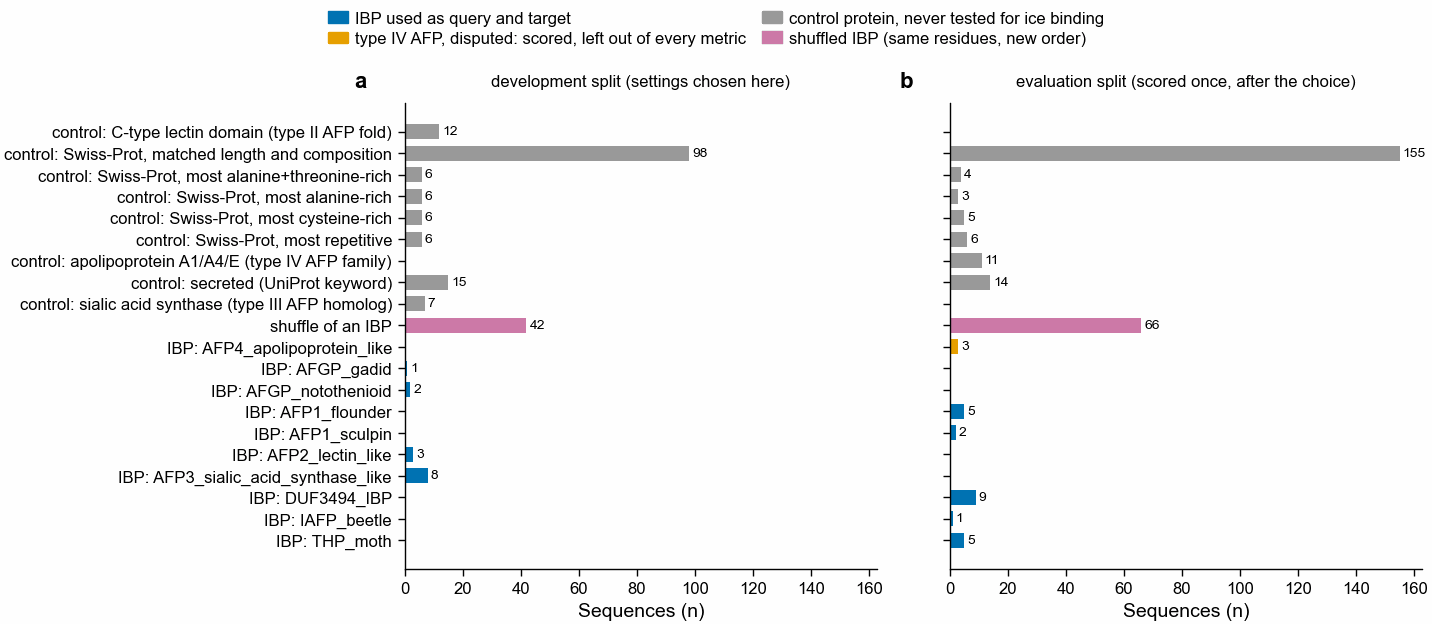

In [2]:
truth = read("truth_manifest.tsv")
print("Truth set entries by origin and evidence on the UniProt FUNCTION comment:")
print(
    truth.group_by("origin_id", "status")
    .agg(
        n_entries=pl.len(),
        n_experimental=pl.col("function_has_experimental_eco").sum(),
        assays=pl.col("assay_named_in_function").unique().str.join(" | "),
    )
    .sort("origin_id")
)

kinds = (
    manifest.filter(pl.col("split") != "excluded")
    .with_columns(
        group=pl.when(pl.col("status").str.starts_with("positive"))
        .then(pl.lit("IBP: ") + pl.col("origin_id"))
        .when(pl.col("status") == "shuffle_control")
        .then(pl.lit("shuffle of an IBP"))
        .otherwise(
            pl.lit("control: ")
            + pl.col("control_category").replace_strict(
                CATEGORY_LABEL, default=pl.col("control_category")
            )
        )
    )
    .group_by("split", "group", "status")
    .agg(n=pl.len(), median_length=pl.col("length").median())
    .sort("split", "status", "group")
)
print(kinds)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 80, ncols=2, sharex=True, sharey=True)
STATUS_COLOUR = {
    "positive": pf.OKABE_ITO["blue"],
    "positive_disputed": pf.OKABE_ITO["orange"],
    "unverified_background": pf.GREY,
    "shuffle_control": pf.OKABE_ITO["reddish_purple"],
}
STATUS_LABEL = {
    "positive": "IBP used as query and target",
    "positive_disputed": "type IV AFP, disputed: scored, left out of every metric",
    "unverified_background": "control protein, never tested for ice binding",
    "shuffle_control": "shuffled IBP (same residues, new order)",
}
groups = (
    kinds.select("group", "status")
    .unique()
    .sort("status", "group", descending=[True, False])
)
order = groups["group"].to_list()
for ax, split in zip(axs, ["dev", "eval"]):
    sub = kinds.filter(pl.col("split") == split)
    for r in sub.iter_rows(named=True):
        y = order.index(r["group"])
        ax.barh(y, r["n"], color=STATUS_COLOUR[r["status"]], height=0.7)
        ax.text(r["n"] + 1, y, str(r["n"]), va="center", fontsize=5)
    ax.set_xlabel("Sequences (n)")
    ax.set_title(
        {
            "dev": "development split (settings chosen here)",
            "eval": "evaluation split (scored once, after the choice)",
        }[split],
        fontsize=6,
    )
axs[0].set_yticks(range(len(order)), order)
axs[0].invert_yaxis()
fig.legend(
    [Patch(color=c) for c in STATUS_COLOUR.values()],
    [STATUS_LABEL[k] for k in STATUS_COLOUR],
    loc="outside upper center",
    ncol=2,
)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "349_F1_panel_composition_swissprot_2026_03")

Panel a is the development split and panel b the evaluation split. Blue bars are the IBPs that
serve as queries; each is aligned to every other bar's sequences in its own split. The two splits
share no control protein: an evaluation control was removed when it aligned to a development
sequence at 40% identity or more, over 50% of the shorter sequence and at least 30 columns, and
scored at least 3 standard deviations above the same pair with the development sequence shuffled
(`leakage.tsv`). The shuffle test is there because identity alone calls any two alanine-rich
proteins homologs. Leaks between IBPs of the two splits are listed but kept, because their
origins are separate by citation. Six evaluation type I AFPs align at 52-61% identity to two
development controls, a serine/threonine-rich GPI-anchored protein (Q5AHC0) and a clathrin coat
assembly protein (Q61548): the first sign that composition will drive the scores.

In [3]:
leak = read("leakage.tsv")
print("Leakage rule hits (evaluation sequence vs closest development sequence):")
print(leak.group_by("eval_status", "action").len())
print(
    leak.filter(pl.col("eval_status") == "positive").sort("identity", descending=True)
)
cand = read("control_candidates.tsv")
print(
    cand.group_by("control_category", "split", "fate")
    .len()
    .sort("control_category", "split", "fate")
)

Leakage rule hits (evaluation sequence vs closest development sequence):
shape: (2, 3)
┌───────────────────────┬────────────────────────────────────────────┬─────┐
│ eval_status           ┆ action                                     ┆ len │
│ ---                   ┆ ---                                        ┆ --- │
│ str                   ┆ str                                        ┆ u32 │
╞═══════════════════════╪════════════════════════════════════════════╪═════╡
│ unverified_background ┆ removed                                    ┆ 13  │
│ positive              ┆ kept (positive of a separate cited origin) ┆ 6   │
└───────────────────────┴────────────────────────────────────────────┴─────┘
shape: (6, 7)
┌─────────────┬─────────────┬────────────────────┬──────────┬──────────┬───────────┬────────────────────────────────────────────┐
│ eval_seq_id ┆ eval_status ┆ closest_dev_seq_id ┆ identity ┆ coverage ┆ shuffle_z ┆ action                                     │
│ ---         ┆ ---    

## 2. Scoring matrices, the parameter grid, and the choice on the development split

For `protein20` the matrices are BLOSUM62 and BLOSUM45 as published. For the reduced alphabets,
each matrix is the source BLOSUM matrix collapsed onto the classes: the pair frequencies behind
BLOSUM are recovered as $\text{Pr}(a,b) = q_a q_b 2^{s_{ab}/2}$ with $q$ the Swiss-Prot 2026_03
residue frequencies, summed over the residues of each class, and turned back into a score
$s(A,B) = 2 \log_2 \frac{\text{Pr}(A,B)}{\text{Pr}(A)\text{Pr}(B)}$. All scores are in half bits, as
in BLOSUM, so a gap cost means the same in every alphabet. A gap of length $L$ costs open $+ L
\times$ extend. Raw scores are never compared across alphabets: each setting gets its own
E-value from a fit on development control pairs (section 7), and methods are compared at the same
false-positive rate.

`hp_lehninger2` puts `AFGILMPVWY` in one class (hydrophobic, H) and `CDEHKNQRST` in the other
(polar, P). `dayhoff6` classes: `C`, `AGPST`, `DENQ`, `FWY`, `HKR`, `ILMV`.

The selection rule, fixed in the config: per alphabet, keep the setting with the highest mean
average precision for other-origin IBPs over development queries. Average precision is the mean,
over the true targets, of the fraction of true targets among all targets ranked at or above it
(1 is perfect; random ranking gives the fraction of targets that are true).

shape: (4, 3)
┌───────────────┬───────────────┬──────────────────────────┐
│ alphabet      ┆ source_matrix ┆ expected_score_half_bits │
│ ---           ┆ ---           ┆ ---                      │
│ str           ┆ str           ┆ f64                      │
╞═══════════════╪═══════════════╪══════════════════════════╡
│ dayhoff6      ┆ BLOSUM62      ┆ -0.741116                │
│ dayhoff6      ┆ BLOSUM45      ┆ -1.024218                │
│ hp_lehninger2 ┆ BLOSUM62      ┆ -0.33976                 │
│ hp_lehninger2 ┆ BLOSUM45      ┆ -0.496021                │
└───────────────┴───────────────┴──────────────────────────┘
hp_lehninger2 BLOSUM45
shape: (2, 3)
┌───────┬──────────┬──────────┐
│ class ┆ H        ┆ P        │
│ ---   ┆ ---      ┆ ---      │
│ str   ┆ f64      ┆ f64      │
╞═══════╪══════════╪══════════╡
│ H     ┆ 1.094784 ┆ -2.23853 │
│ P     ┆ -2.23853 ┆ 1.411806 │
└───────┴──────────┴──────────┘
hp_lehninger2 BLOSUM62
shape: (2, 3)
┌───────┬───────────┬───────────┐
│ class ┆ H 

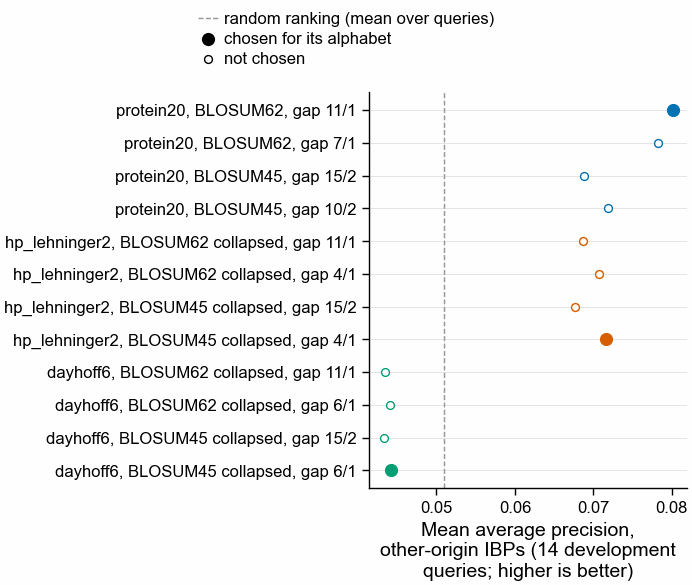

In [4]:
mats = read("matrices.tsv")
reduced = mats.filter(pl.col("alphabet") != "protein20")
print(
    reduced.group_by("alphabet", "source_matrix")
    .agg(expected_score_half_bits=pl.col("expected_score_half_bits").first())
    .sort("alphabet")
)
for (alph, src), g in reduced.group_by(
    ["alphabet", "source_matrix"], maintain_order=True
):
    print(alph, src)
    print(
        g.select(pl.col("a").alias("class"), "b", "score_half_bits").pivot(
            on="b", index="class", values="score_half_bits"
        )
    )

grid = read("dev_grid_metrics.tsv")
print(grid)
dev_q = read("metrics_per_query.tsv").filter(
    (pl.col("split") == "dev")
    & (pl.col("setting") == REFERENCE)
    & (pl.col("task") == "cross_origin_positive")
)
random_ap = float(
    (dev_q["n_positives"] / (dev_q["n_positives"] + dev_q["n_negatives"])).mean()
)
print(
    f"mean over development queries of the average precision a random ranking gives: {random_ap:.3f}"
)

fig, axs = pf.figure(pf.ONE_COLUMN_MM, 75, ncols=1)
ax = axs if not isinstance(axs, np.ndarray) else axs[0]
labels = grid["setting"].to_list()
for i, r in enumerate(grid.iter_rows(named=True)):
    chosen = r["setting"] in SELECTED
    ax.scatter(
        r["mean_cross_origin_average_precision"],
        i,
        s=18 if chosen else 8,
        color=ALPHABET_COLOUR[r["alphabet"]],
        facecolor=ALPHABET_COLOUR[r["alphabet"]] if chosen else "white",
        zorder=3,
    )
ax.axvline(random_ap, color=pf.GREY, lw=0.5, ls="--")
ax.plot(
    [], [], color=pf.GREY, lw=0.5, ls="--", label="random ranking (mean over queries)"
)
ax.set_yticks(
    range(len(labels)), [method_label(s).replace("Smith-Waterman ", "") for s in labels]
)
for i in range(len(labels)):
    ax.axhline(i, color="#dddddd", lw=0.3, zorder=0)
ax.invert_yaxis()
ax.set_xlabel(
    "Mean average precision,\nother-origin IBPs (14 development\nqueries; higher is better)"
)
ax.scatter([], [], s=18, color="black", label="chosen for its alphabet")
ax.scatter([], [], s=8, facecolor="white", color="black", label="not chosen")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "349_F2_development_grid_choice_swissprot_2026_03")

Every setting sits within 0.04 of the random-ranking line on the development split, and the
Dayhoff settings sit below it: the choice is made between settings that are all close to chance
at finding other-origin IBPs, so it rests on small differences. Within an origin the same settings work (section 3, open markers), so the alignments
themselves are not broken.

## 3. Headline: other-origin IBPs against controls and shuffles, evaluation split

Evaluation split: 22 IBP queries from five origins (type I flounder, type I sculpin, moth,
beetle, DUF3494), each aligned to every other sequence in the split. A true target is an IBP of a
different origin (348 query-target pairs). Negatives are the 198 control proteins (4_356 pairs).
Shuffles are scored but never counted as negatives here.

shape: (9, 8)
┌────────────────────────────────────┬──────────────────┬──────────────────┬────────────┬──────────────────────────────┬────────────────────────┬─────────────────────────────┬─────────────────┐
│ setting                            ┆ n_positive_pairs ┆ n_negative_pairs ┆ pooled_auc ┆ recall_other_origin_fpr_1pct ┆ pooled_recall_fpr_0.05 ┆ recall_same_origin_fpr_1pct ┆ auc_vs_shuffles │
│ ---                                ┆ ---              ┆ ---              ┆ ---        ┆ ---                          ┆ ---                    ┆ ---                         ┆ ---             │
│ str                                ┆ i64              ┆ i64              ┆ f64        ┆ f64                          ┆ f64                    ┆ f64                         ┆ f64             │
╞════════════════════════════════════╪══════════════════╪══════════════════╪════════════╪══════════════════════════════╪════════════════════════╪═════════════════════════════╪═════════════════╡
│ baseline_targe

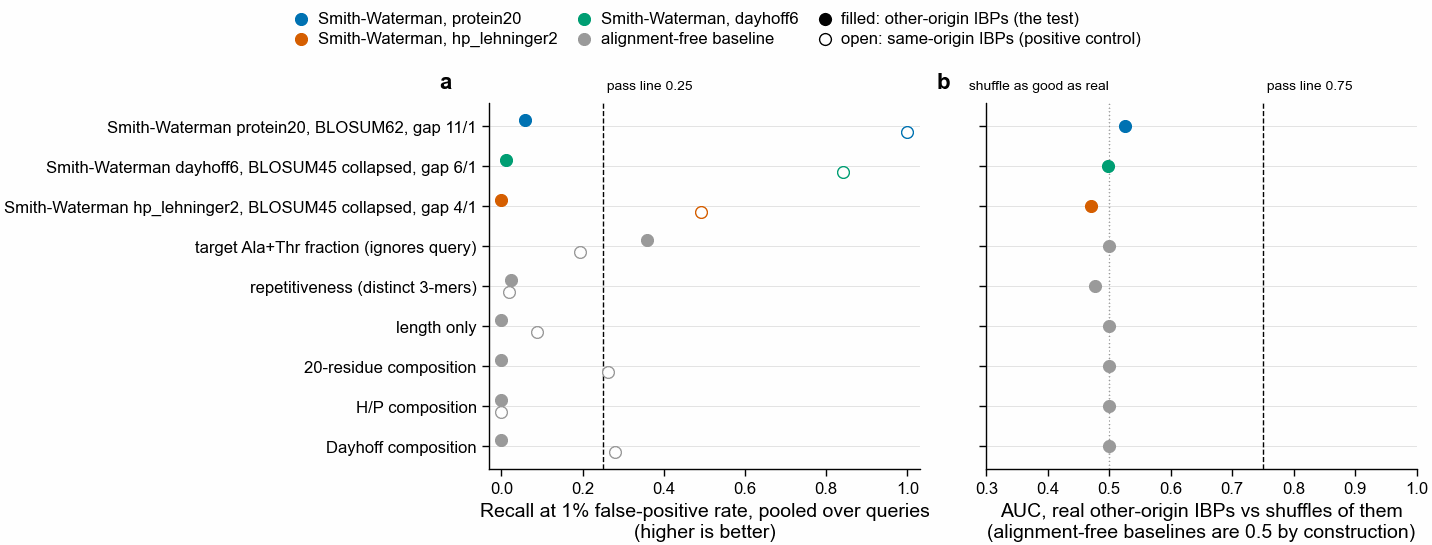

In [5]:
pooled = read("metrics_pooled.tsv")
controls = read("control_comparison.tsv")
decision = read("decision.tsv")
ev = pooled.filter(pl.col("split") == "eval")
cross = ev.filter(pl.col("task") == "cross_origin_positive")
within = ev.filter(pl.col("task") == "same_origin_positive")
shuf = controls.filter(
    (pl.col("split") == "eval")
    & (pl.col("control") == "shuffles_of_the_cross_origin_targets")
)
table = (
    cross.select(
        "setting",
        "n_positive_pairs",
        "n_negative_pairs",
        "pooled_auc",
        pl.col("pooled_recall_fpr_0.01").alias("recall_other_origin_fpr_1pct"),
        "pooled_recall_fpr_0.05",
    )
    .join(
        within.select(
            "setting",
            pl.col("pooled_recall_fpr_0.01").alias("recall_same_origin_fpr_1pct"),
        ),
        on="setting",
    )
    .join(
        shuf.select(
            "setting", pl.col("auc_cross_origin_vs_control").alias("auc_vs_shuffles")
        ),
        on="setting",
    )
    .with_columns(
        method=pl.col("setting").map_elements(method_label, return_dtype=pl.Utf8)
    )
    .sort("recall_other_origin_fpr_1pct", descending=True)
)
print(table.drop("method"))
print(decision.select("level", "name", "separates", "reason"))
print("OUTCOME:", decision["outcome"][0])

order = (
    table.with_columns(is_base=pl.col("setting").str.starts_with("baseline_")).sort(
        ["is_base", "recall_other_origin_fpr_1pct"], descending=[False, True]
    )
)["setting"].to_list()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 70, ncols=2, sharey=True)
for i, s in enumerate(order):
    r = table.filter(pl.col("setting") == s).row(0, named=True)
    c = method_colour(s)
    axs[0].scatter(r["recall_other_origin_fpr_1pct"], i - 0.15, s=18, color=c, zorder=3)
    axs[0].scatter(
        r["recall_same_origin_fpr_1pct"],
        i + 0.15,
        s=18,
        facecolor="white",
        color=c,
        zorder=3,
    )
    axs[1].scatter(r["auc_vs_shuffles"], i, s=18, color=c, zorder=3)
    for ax in axs:
        ax.axhline(i, color="#dddddd", lw=0.3, zorder=0)
axs[0].axvline(0.25, color="black", lw=0.5, ls="--")
axs[0].text(0.25, -0.9, " pass line 0.25", fontsize=5)
axs[1].axvline(0.75, color="black", lw=0.5, ls="--")
axs[1].text(0.75, -0.9, " pass line 0.75", fontsize=5)
axs[1].axvline(0.5, color=pf.GREY, lw=0.5, ls=":")
axs[1].text(0.5, -0.9, " shuffle as good as real", fontsize=5, ha="right")
axs[0].set_yticks(range(len(order)), [method_label(s) for s in order])
axs[0].invert_yaxis()
axs[0].set_xlim(-0.03, 1.03)
axs[1].set_xlim(0.3, 1.0)
axs[0].set_xlabel(
    "Recall at 1% false-positive rate, pooled over queries\n(higher is better)"
)
axs[1].set_xlabel(
    "AUC, real other-origin IBPs vs shuffles of them\n(alignment-free baselines are 0.5 by construction)"
)
for name, colour in [
    ("Smith-Waterman, protein20", ALPHABET_COLOUR["protein20"]),
    ("Smith-Waterman, hp_lehninger2", ALPHABET_COLOUR["hp_lehninger2"]),
    ("Smith-Waterman, dayhoff6", ALPHABET_COLOUR["dayhoff6"]),
    ("alignment-free baseline", pf.GREY),
]:
    axs[0].scatter([], [], s=18, color=colour, label=name)
axs[0].scatter(
    [], [], s=18, color="black", label="filled: other-origin IBPs (the test)"
)
axs[0].scatter(
    [],
    [],
    s=18,
    facecolor="white",
    color="black",
    label="open: same-origin IBPs (positive control)",
)
pf.shared_legend(fig, ncol=3)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "349_F3_headline_recall_and_shuffles_eval_swissprot_2026_03")

How to read it: in panel a a filled dot right of the dashed line finds at least a quarter of the
other-origin IBPs before 1% of control pairs score higher. In panel b a dot right of the dashed
line means the real protein beats its own shuffled residues, so residue order carries the score.

No alignment passes either line on the whole evaluation set. The best of them, protein20 with
BLOSUM62 and gap 11/1, finds 5.7% of other-origin pairs at 1% false positives, and the reduced
alphabets find 0% (H/P) and 1.1% (Dayhoff). A rule that ignores the query, ranking targets by
their alanine plus threonine fraction, finds 35.9%. Shuffled IBPs score as well as the real ones
(AUC 0.47 to 0.53). The same alignments find 49% to 100% of same-origin IBPs at 1% false
positives (open markers): they work as homology search, but they do not see a shared ice-binding
signal across origins.

## 4. Where the scores come from: every kind of target

Each point is one query-target pair, scored as $-\log_{10}$ of the E-value from the development fit
(higher is a stronger match). Rows are the kinds of target. If alignment saw an ice-binding signal,
the top row would sit to the right of every control row and of the shuffle row.

shape: (40, 5)
┌──────────────────────────────────┬──────────────────────────────────────────────────────┬─────────┬───────────┬───────────┐
│ setting                          ┆ row                                                  ┆ n_pairs ┆ median    ┆ q90       │
│ ---                              ┆ ---                                                  ┆ ---     ┆ ---       ┆ ---       │
│ str                              ┆ str                                                  ┆ u32     ┆ f64       ┆ f64       │
╞══════════════════════════════════╪══════════════════════════════════════════════════════╪═════════╪═══════════╪═══════════╡
│ baseline_target_ala_thr_fraction ┆ IBP, other origin (the test)                         ┆ 348     ┆ 0.268124  ┆ 0.795918  │
│ baseline_target_ala_thr_fraction ┆ IBP, same origin (positive control)                  ┆ 114     ┆ 0.242063  ┆ 0.795918  │
│ baseline_target_ala_thr_fraction ┆ control: Swiss-Prot, matched length and composition  ┆ 3410    ┆ 0

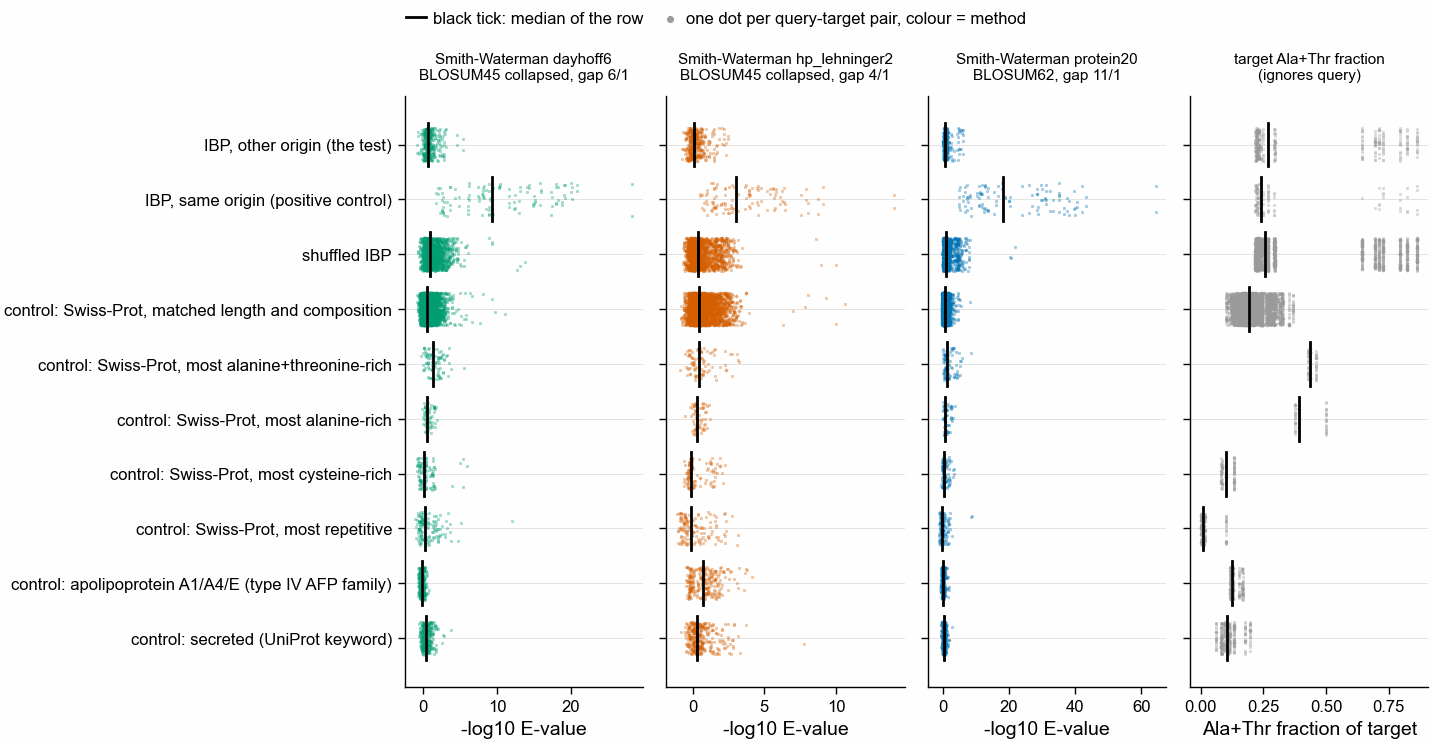

In [6]:
ranked = read("ranked_results.tsv.gz")
ev_rank = ranked.filter(pl.col("split") == "eval")
row_of = (
    pl.when(pl.col("role") == "cross_origin_positive")
    .then(pl.lit("IBP, other origin (the test)"))
    .when(pl.col("role") == "same_origin_positive")
    .then(pl.lit("IBP, same origin (positive control)"))
    .when(pl.col("role") == "shuffle")
    .then(pl.lit("shuffled IBP"))
    .when(pl.col("role") == "real_negative")
    .then(
        pl.lit("control: ")
        + pl.col("t_category").replace_strict(
            CATEGORY_LABEL, default=pl.col("t_category")
        )
    )
    .otherwise(None)
)
ev_rank = ev_rank.with_columns(row=row_of).filter(pl.col("row").is_not_null())
rows = [
    "IBP, other origin (the test)",
    "IBP, same origin (positive control)",
    "shuffled IBP",
] + sorted(ev_rank.filter(pl.col("role") == "real_negative")["row"].unique().to_list())
show = SELECTED + ["baseline_target_ala_thr_fraction"]
summary = (
    ev_rank.filter(pl.col("setting").is_in(show))
    .group_by("setting", "row")
    .agg(
        n_pairs=pl.len(), median=pl.col("sim").median(), q90=pl.col("sim").quantile(0.9)
    )
    .sort("setting", "row")
)
print(summary)

rng = np.random.default_rng(349)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=len(show), sharey=True)
for ax, s in zip(axs, show):
    sub = ev_rank.filter(pl.col("setting") == s)
    for i, row in enumerate(rows):
        v = sub.filter(pl.col("row") == row)["sim"].to_numpy()
        if not len(v):
            continue
        y = i + rng.uniform(-0.3, 0.3, len(v))
        ax.scatter(
            v,
            y,
            s=1.5,
            color=method_colour(s),
            alpha=0.35,
            linewidths=0,
            rasterized=True,
        )
        ax.plot([np.median(v)] * 2, [i - 0.4, i + 0.4], color="black", lw=1)
        ax.axhline(i, color="#dddddd", lw=0.3, zorder=0)
    ax.set_title(
        method_label(s)
        .replace(", BLOSUM", "\nBLOSUM")
        .replace(" (ignores query)", "\n(ignores query)"),
        fontsize=5.5,
    )
    ax.set_xlabel(
        "Ala+Thr fraction of target" if s.startswith("baseline") else "-log10 E-value"
    )
axs[0].set_yticks(range(len(rows)), rows)
axs[0].invert_yaxis()
axs[0].plot([], [], color="black", lw=1, label="black tick: median of the row")
axs[0].scatter(
    [], [], s=4, color=pf.GREY, label="one dot per query-target pair, colour = method"
)
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / "349_F4_scores_by_target_kind_eval_swissprot_2026_03")

In every alignment panel the shuffled IBPs (third row) score like the real other-origin IBPs
(first row), with medians within 0.5 of each other, and every control row overlaps both. Only the
same-origin row stands apart. In the last panel the other-origin row splits in two: the
alanine-rich type I AFPs at 0.6 to 0.9 Ala+Thr, the rest near 0.25. A score that looks only at the
target finds the type I AFPs for every query.

## 5. Per query origin

Each point is one query: its average precision for other-origin IBPs (higher is better; the dashed
line is a random ranking for that origin's queries). The type I and insect queries do best, and
the composition-only baseline does as well or better for every origin.

shape: (25, 6)
┌──────────────────────────────────┬───────────────┬───────────┬────────────────────────┬──────────────────────┬───────────────────────────┐
│ setting                          ┆ q_origin      ┆ n_queries ┆ mean_average_precision ┆ mean_recall_fpr_0.01 ┆ median_best_positive_rank │
│ ---                              ┆ ---           ┆ ---       ┆ ---                    ┆ ---                  ┆ ---                       │
│ str                              ┆ str           ┆ i64       ┆ f64                    ┆ f64                  ┆ f64                       │
╞══════════════════════════════════╪═══════════════╪═══════════╪════════════════════════╪══════════════════════╪═══════════════════════════╡
│ baseline_composition20           ┆ AFP1_flounder ┆ 5         ┆ 0.203733               ┆ 0.117647             ┆ 1.0                       │
│ baseline_target_ala_thr_fraction ┆ AFP1_flounder ┆ 5         ┆ 0.28179                ┆ 0.117647             ┆ 1.0                       

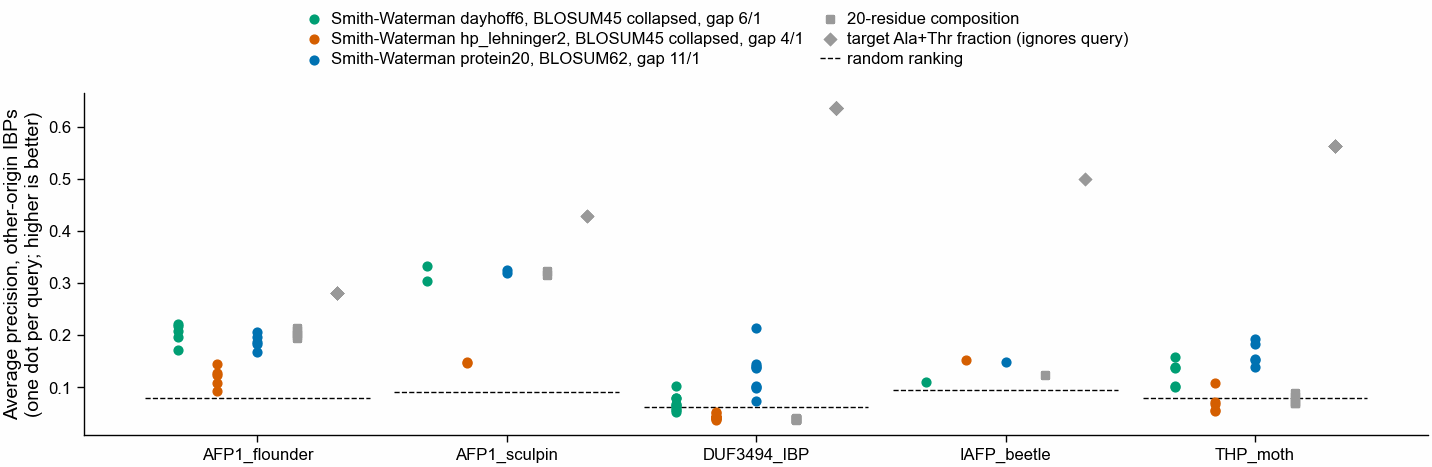

In [7]:
perq = read("metrics_per_query.tsv").filter(
    (pl.col("split") == "eval") & (pl.col("task") == "cross_origin_positive")
)
show = SELECTED + ["baseline_composition20", "baseline_target_ala_thr_fraction"]
per_origin = read("metrics_per_origin.tsv").filter(
    (pl.col("split") == "eval")
    & (pl.col("task") == "cross_origin_positive")
    & pl.col("setting").is_in(show)
)
print(
    per_origin.select(
        "setting",
        "q_origin",
        "n_queries",
        "mean_average_precision",
        "mean_recall_fpr_0.01",
        "median_best_positive_rank",
    ).sort("q_origin", "setting")
)
origins = sorted(perq["q_origin"].unique().to_list())
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 60, ncols=1)
ax = axs if not isinstance(axs, np.ndarray) else axs[0]
width = 0.8 / len(show)
for j, s in enumerate(show):
    sub = perq.filter(pl.col("setting") == s)
    for i, o in enumerate(origins):
        v = sub.filter(pl.col("q_origin") == o)
        x = i - 0.4 + width * (j + 0.5)
        marker = (
            "o"
            if not s.startswith("baseline")
            else ("s" if "composition20" in s else "D")
        )
        ax.scatter(
            [x] * v.height,
            v["average_precision"],
            s=10,
            color=method_colour(s),
            marker=marker,
            zorder=3,
        )
for i, o in enumerate(origins):
    v = perq.filter((pl.col("setting") == REFERENCE) & (pl.col("q_origin") == o))
    rand = (v["n_positives"] / (v["n_positives"] + v["n_negatives"])).mean()
    ax.plot([i - 0.45, i + 0.45], [rand, rand], color="black", lw=0.5, ls="--")
ax.set_xticks(range(len(origins)), origins)
ax.set_ylabel(
    "Average precision, other-origin IBPs\n(one dot per query; higher is better)"
)
for s in show:
    marker = (
        "o" if not s.startswith("baseline") else ("s" if "composition20" in s else "D")
    )
    ax.scatter(
        [], [], s=10, color=method_colour(s), marker=marker, label=method_label(s)
    )
ax.plot([], [], color="black", lw=0.5, ls="--", label="random ranking")
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / "349_F5_per_origin_average_precision_eval_swissprot_2026_03")

## 6. Subgroups declared before the run

Three subgroups were written into the config before the evaluation split was scored, each with a
paper or a UniProt family behind it. A subgroup is scored with the same three-part rule, on its own
queries and targets plus all controls. The AFGP subgroup lies in the development split, which chose
the settings, so its numbers are not an independent test.

shape: (27, 8)
┌──────────────────────────────────────────┬───────┬────────────────────────────────────┬──────────────────┬──────────────────┬────────────────────────┬────────────┬────────────────────────────┐
│ subgroup                                 ┆ split ┆ setting                            ┆ n_positive_pairs ┆ n_negative_pairs ┆ pooled_recall_fpr_0.01 ┆ pooled_auc ┆ auc_vs_shuffles_of_targets │
│ ---                                      ┆ ---   ┆ ---                                ┆ ---              ┆ ---              ┆ ---                    ┆ ---        ┆ ---                        │
│ str                                      ┆ str   ┆ str                                ┆ i64              ┆ i64              ┆ f64                    ┆ f64        ┆ f64                        │
╞══════════════════════════════════════════╪═══════╪════════════════════════════════════╪══════════════════╪══════════════════╪════════════════════════╪════════════╪════════════════════════════╡
│ AFGP, no

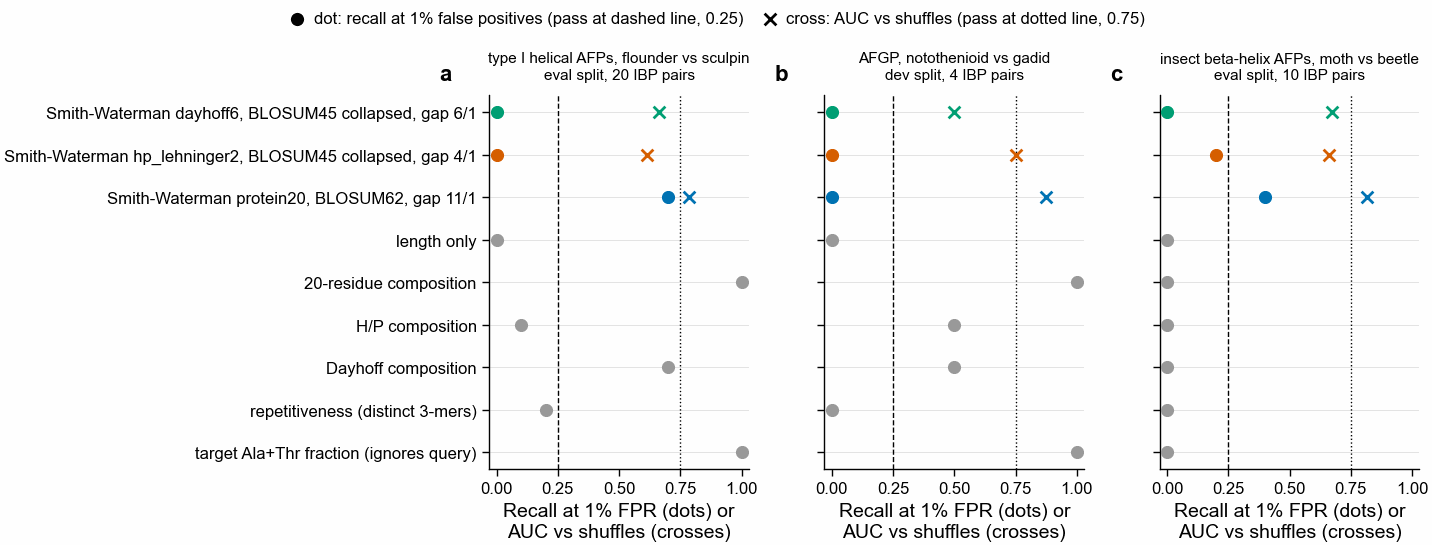

In [8]:
subs = read("subgroup_metrics.tsv")
print(
    subs.drop("basis").sort(
        "subgroup", "split", "pooled_recall_fpr_0.01", descending=[False, False, True]
    )
)
names = [s for s in subs["subgroup"].unique(maintain_order=True)]
show = SELECTED + list(BASELINE_LABEL)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 70, ncols=3, sharey=True)
for ax, name in zip(axs, names):
    sub = subs.filter(pl.col("subgroup") == name)
    split = sub["split"][0]
    for i, s in enumerate(show):
        r = sub.filter(pl.col("setting") == s)
        if not r.height:
            continue
        r = r.row(0, named=True)
        ax.scatter(
            r["pooled_recall_fpr_0.01"], i, s=18, color=method_colour(s), zorder=3
        )
        if not s.startswith("baseline"):
            ax.scatter(
                r["auc_vs_shuffles_of_targets"],
                i,
                s=18,
                marker="x",
                color=method_colour(s),
                zorder=3,
            )
        ax.axhline(i, color="#dddddd", lw=0.3, zorder=0)
    ax.axvline(0.25, color="black", lw=0.5, ls="--")
    ax.axvline(0.75, color="black", lw=0.5, ls=":")
    n_pos = sub["n_positive_pairs"][0]
    ax.set_title(f"{name}\n{split} split, {n_pos} IBP pairs", fontsize=5.5)
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel("Recall at 1% FPR (dots) or\nAUC vs shuffles (crosses)")
axs[0].set_yticks(range(len(show)), [method_label(s) for s in show])
axs[0].invert_yaxis()
axs[0].scatter(
    [],
    [],
    s=18,
    color="black",
    label="dot: recall at 1% false positives (pass at dashed line, 0.25)",
)
axs[0].scatter(
    [],
    [],
    s=18,
    color="black",
    marker="x",
    label="cross: AUC vs shuffles (pass at dotted line, 0.75)",
)
pf.shared_legend(fig, ncol=2)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "349_F6_subgroups_swissprot_2026_03")

The type I subgroup (panel a) has high alignment recall, 0.70 for protein20, but the 20-residue
composition baseline and the Ala+Thr fraction both reach 1.0: these are alanine-rich helices
found by their alanine. The AFGP subgroup (panel b, development split) is found by composition and
by Ala+Thr fraction (1.0), and by no alignment at 1% false positives, because the 16-31 residue
AFGPs are too short for their alignment to beat long alanine-rich controls.

The moth-beetle subgroup (panel c) is the only one that passes the rule, for protein20 only:
recall 0.40, margin +0.40 over the best baseline, AUC 0.82 against shuffles. It rests on one beetle
protein (O16119) and 10 pairs, at E-values of 0.002 to 0.008, and it holds only with the moth AFPs
as queries. With the beetle AFP as query, its own shuffles and shuffled moth AFPs rank above every
real moth AFP (ranks 1 to 4 below). It is the rule's literal outcome and the weakest possible form
of it.

In [9]:
beetle = (
    ranked.filter((pl.col("setting") == REFERENCE) & (pl.col("query") == "O16119"))
    .sort("rank")
    .head(12)
    .join(
        manifest.select(pl.col("seq_id").alias("target"), "protein_name"),
        on="target",
        how="left",
    )
    .select("rank", "target", "role", "t_category", "score", "evalue", "protein_name")
)
print("Top 12 targets of the beetle AFP O16119 (protein20, BLOSUM62, gap 11/1):")
print(beetle)
moth = ranked.filter(
    (pl.col("setting") == REFERENCE)
    & pl.col("query").str.starts_with("Q9G")
    & (pl.col("target") == "O16119")
).select(
    "query", "target", "rank", "score", "evalue", "identical_residues", "aln_columns"
)
print("Beetle AFP as the target of each moth AFP query:")
print(moth)

Top 12 targets of the beetle AFP O16119 (protein20, BLOSUM62, gap 11/1):
shape: (12, 7)
┌──────┬───────────────┬───────────────┬─────────────────────┬───────┬─────────────────────────┬─────────────────────────────────┐
│ rank ┆ target        ┆ role          ┆ t_category          ┆ score ┆ evalue                  ┆ protein_name                    │
│ ---  ┆ ---           ┆ ---           ┆ ---                 ┆ ---   ┆ ---                     ┆ ---                             │
│ i64  ┆ str           ┆ str           ┆ str                 ┆ str   ┆ str                     ┆ str                             │
╞══════╪═══════════════╪═══════════════╪═════════════════════╪═══════╪═════════════════════════╪═════════════════════════════════╡
│ 1    ┆ O16119__shuf0 ┆ shuffle       ┆ shuffle_of_positive ┆ 76.0  ┆ 0.000060584231783216374 ┆ shuffle 0 of O16119             │
│ 2    ┆ O16119__shuf1 ┆ shuffle       ┆ shuffle_of_positive ┆ 74.0  ┆ 0.00008377990328140558  ┆ shuffle 1 of O16119          

## 7. Calibration: are the E-values right on new data?

E-values come from a fit of $\text{Pr}(S \ge x) = 1 - e^{-K m n e^{-\lambda x}}$ to development
control pairs ($m$, $n$ the two sequence lengths), one $\lambda$ and $K$ per setting. If they are
right, the fraction of control pairs with $\text{Pr} \le \alpha$ equals $\alpha$ (the diagonal). A
point above the diagonal means more chance hits than the E-value promises.

shape: (12, 6)
┌─────────────────────────┬───────────────┬──────────┬──────────┬──────────────┬─────────────────────────┐
│ setting                 ┆ alphabet      ┆ lambda   ┆ K        ┆ n_null_pairs ┆ fit_on                  │
│ ---                     ┆ ---           ┆ ---      ┆ ---      ┆ ---          ┆ ---                     │
│ str                     ┆ str           ┆ f64      ┆ f64      ┆ i64          ┆ str                     │
╞═════════════════════════╪═══════════════╪══════════╪══════════╪══════════════╪═════════════════════════╡
│ protein20_B62_g11e1     ┆ protein20     ┆ 0.162079 ┆ 0.001921 ┆ 2184         ┆ dev real_negative pairs │
│ protein20_B62_g7e1      ┆ protein20     ┆ 0.130985 ┆ 0.001267 ┆ 2184         ┆ dev real_negative pairs │
│ protein20_B45_g15e2     ┆ protein20     ┆ 0.122896 ┆ 0.001856 ┆ 2184         ┆ dev real_negative pairs │
│ protein20_B45_g10e2     ┆ protein20     ┆ 0.111982 ┆ 0.001529 ┆ 2184         ┆ dev real_negative pairs │
│ hp_lehninger2_B62_g1

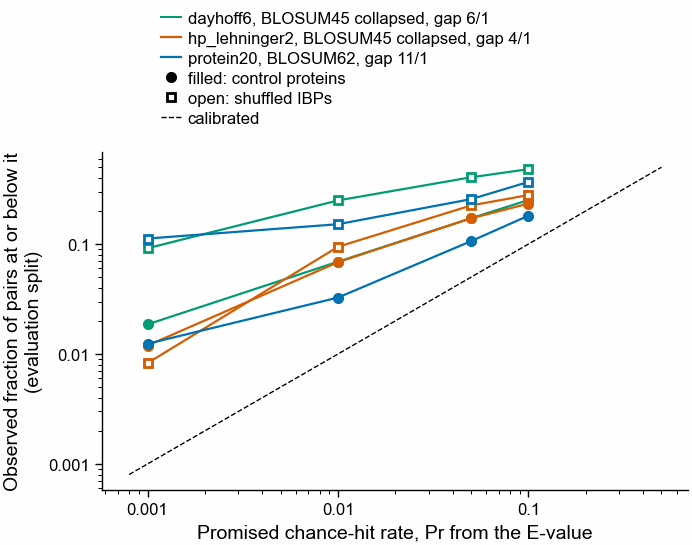

In [10]:
cal = read("calibration.tsv")
print(cal)
chk = read("calibration_check.tsv")
print(chk.filter(pl.col("p_threshold") == 0.01))
fig, axs = pf.figure(pf.ONE_COLUMN_MM, 70, ncols=1)
ax = axs if not isinstance(axs, np.ndarray) else axs[0]
for (split, setting, pairs), g in chk.group_by(
    ["split", "setting", "pairs"], maintain_order=True
):
    if split != "eval":
        continue
    g = g.sort("p_threshold")
    ax.plot(
        g["p_threshold"],
        g["observed_fraction"],
        color=method_colour(setting),
        marker="o" if pairs == "real_negative" else "s",
        ms=3,
        mfc=method_colour(setting) if pairs == "real_negative" else "white",
        lw=0.8,
    )
lim = [0.0008, 0.5]
ax.plot(lim, lim, color="black", lw=0.5, ls="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([0.001, 0.01, 0.1], ["0.001", "0.01", "0.1"])
ax.set_yticks([0.001, 0.01, 0.1], ["0.001", "0.01", "0.1"])
ax.set_xlabel("Promised chance-hit rate, Pr from the E-value")
ax.set_ylabel("Observed fraction of pairs at or below it\n(evaluation split)")
for s in SELECTED:
    ax.plot(
        [],
        [],
        color=method_colour(s),
        lw=0.8,
        label=method_label(s).replace("Smith-Waterman ", ""),
    )
ax.plot(
    [], [], marker="o", color="black", ls="", ms=3, label="filled: control proteins"
)
ax.plot(
    [],
    [],
    marker="s",
    mfc="white",
    color="black",
    ls="",
    ms=3,
    label="open: shuffled IBPs",
)
ax.plot([], [], color="black", lw=0.5, ls="--", label="calibrated")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "349_F7_calibration_eval_swissprot_2026_03")

The axes are spaced by ratio: the step from 0.001 to 0.01 takes as much room as 0.01 to 0.1.
On evaluation controls, protein20 sees 3.3% of pairs at Pr ≤ 0.01 instead of 1%, and the reduced
alphabets about 7%. Shuffled IBPs reach 9% to 25%. A shuffled IBP is a better match to an IBP query
than a real control is, so the E-values over-reward composition. The development control pairs the
fit was made on are off by the same amount (3.6% for protein20 at Pr ≤ 0.01, table above): the
score tail is heavier than the fitted curve allows, on both splits. This is why the rule compares methods at a false-positive rate
measured on controls, not at an E-value cut-off. For comparison, at E = 10 (Pr ≈ 1) nearly every
pair passes, so no E = 10 result is shown.

## 8. Representative alignments, real residues

For each evaluation query origin, the best-scoring other-origin IBP and the best-scoring control,
with the selected setting of each alphabet. `|` marks an identical residue, `:` the same class in
the alphabet aligned, a space a different class. Coordinates are on the mature sequence.

In [11]:
print((DATA / "representative_alignments.txt").read_text())

Real residues shown; '|' identical residue, ':' same class in the alphabet aligned, ' ' different class.

## protein20_B62_g11e1 | query origin AFP1_flounder | best cross_origin_positive
query  P09031 (Ice-structuring protein (ISP) (Antifreeze protein) (AFP)) 1-42
target P04368 (Ice-structuring protein SS-8 (ISP SS-8) (Antifreeze peptide SS-8)) 4-45
score 96.0 half bits, E = 7.4e-07

  query  DTASDAAAAAAATAAAAAKAAADTAAAAAKAAADTAAAAAEA
          |    ||  || || ||| ||| || ||  ||  ||||| |
  target ETPAQKAARLAAAAALAAKTAADAAAKAAAKAAAIAAAAASA

## protein20_B62_g11e1 | query origin AFP1_flounder | best real_negative
query  B1P0S1 (Antifreeze protein Maxi (5a-like AFP) (Type 1 hyperactive antifreeze protein) (AFP Hyp-1)) 2-160
target Q40237 (Major pollen allergen Lol p 5b) 148-309
score 151.0 half bits, E = 2.76e-09

  query  IDPAARAAAAAAASKAAVTAADAAAAAATIAASAASVAAATAADDAAASIATINAASAAAKSIAAAAAMAAKDTAAAAASAAAAAVASAAKALETINVKAAYAAATTAN------TAAAAAAATATTAAAAAAAKATIDNAAAAKAAAVATAVSDAAATAATAAA
    

The pattern repeats in every block. The flounder type I AFP P09031 and the sculpin AFP P04368 align
at E = 7.4e-7 over 42 residues, and almost every identical residue is an alanine. The best control
for the flounder Maxi AFP B1P0S1 is the grass pollen allergen Lol p 5b, at E = 2.8e-9, through its
Ala-Thr-Pro repeats: a control beats the other-origin IBP. The bacterial IBP Q086E4 aligns best to
a poly-serine protein (Q75JC9, E = 2e-9).

## 9. Runtime and peak memory

One process on a laptop CPU (Apple silicon, one core). Peak memory is the largest resident set
size the process reached by the end of that step.

shape: (23, 5)
┌──────────┬────────────────────────────────────────┬──────────────┬─────────────┬─────────────────────┐
│ step     ┆ detail                                 ┆ wall_seconds ┆ peak_rss_mb ┆ finished_at         │
│ ---      ┆ ---                                    ┆ ---          ┆ ---         ┆ ---                 │
│ str      ┆ str                                    ┆ f64          ┆ f64         ┆ str                 │
╞══════════╪════════════════════════════════════════╪══════════════╪═════════════╪═════════════════════╡
│ manifest ┆ null                                   ┆ 0.01         ┆ 214.3       ┆ 2026-10-19T14:21:27 │
│ panel    ┆ null                                   ┆ 50.44        ┆ 442.5       ┆ 2026-10-19T14:22:18 │
│ panel    ┆ null                                   ┆ 44.24        ┆ 450.5       ┆ 2026-10-19T14:23:23 │
│ panel    ┆ null                                   ┆ 47.21        ┆ 452.4       ┆ 2026-10-19T14:24:31 │
│ align    ┆ dev protein20_B62_g11e1 295

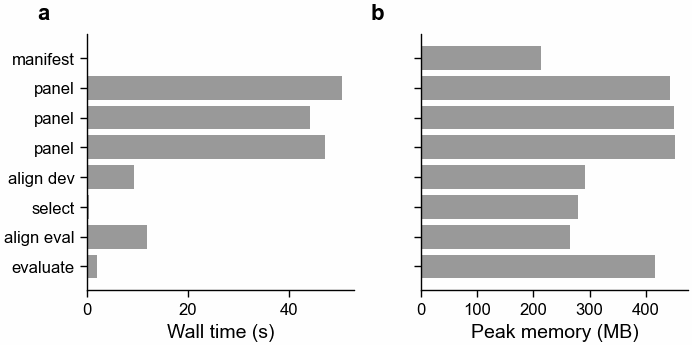

In [12]:
rt = read("runtime.tsv")
print(rt)
steps = rt.filter(~pl.col("step").eq("align") | pl.col("detail").is_in(["dev", "eval"]))
fig, axs = pf.figure(pf.ONE_COLUMN_MM, 45, ncols=2)
labels = [
    f"{r['step']} {r['detail'] or ''}".strip() for r in steps.iter_rows(named=True)
]
axs[0].barh(range(len(labels)), steps["wall_seconds"], color=pf.GREY)
axs[1].barh(range(len(labels)), steps["peak_rss_mb"], color=pf.GREY)
axs[0].set_yticks(range(len(labels)), labels)
axs[1].set_yticks(range(len(labels)), [""] * len(labels))
for ax in axs:
    ax.invert_yaxis()
axs[0].set_xlabel("Wall time (s)")
axs[1].set_xlabel("Peak memory (MB)")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "349_F8_runtime_memory_laptop")

## 10. Data gaps

* No experimentally supported negatives. Every control is "never tested for ice binding". A
  control that does bind ice would count as a false positive.
* Only two origin pairs have a paper showing separate origins (type I flounder vs sculpin; AFGP
  notothenioid vs gadid). Moth vs beetle rests on separate UniProt families and repeat lengths.
* One beetle sequence (O16119) and, after collapsing near-duplicates, one gadid AFGP (P11920, 19
  residues). Those origins have no same-origin positive control.
* No plant IBP is in reviewed Swiss-Prot, so no plant origin.
* Type IV AFP is disputed and left out; P86268 (Antarctomyces) has no origin rule and is left out.
* Assay type comes from the wording of UniProt FUNCTION comments; 43 of 59 entries have no
  experimental evidence code (ECO:0000269) on that comment.
* Both splits were looked at before, by notebooks 295 and 298 with kmerseek.

## Summary & Conclusions

**Outcome under the predeclared rule: "only a narrow subgroup shows signal"**, and that subgroup
(moth vs beetle, protein20 only) rests on one beetle protein, 10 pairs and E-values of 0.002-0.008,
and fails in the beetle-as-query direction. Read with that caveat, the result is close to the
fourth outcome: no tested linear scoring method separates IBPs of separate origins from controls.

1. Seedless Smith-Waterman alignment does not find IBPs of other origins in Swiss-Prot controls:
   at 1% false positives it recovers 5.7% of other-origin pairs with the 20 amino acids, 0% with
   `hp_lehninger2` and 1.1% with `dayhoff6`, against 35.9% for a rule that only ranks targets by
   alanine plus threonine fraction (section 3).
2. These alignments show no pooled advantage of residue order across origins: shuffled IBPs score as well as the real proteins
   (AUC 0.47-0.53 against 0.75 needed), while the same alignments recover 49-100% of same-origin
   IBPs (section 3).
3. Reduction hurts here. H/P and Dayhoff are below protein20 on every measure, and their E-values
   are worse calibrated, about 7% of unverified control pairs below a fitted 0.01 chance-probability cutoff (sections 3, 7).
4. The type I AFP pair that evolved separately (flounder vs sculpin) aligns at E = 7.4e-7, but a
   20-residue composition score already finds all 20 of those pairs at 1% false positives: the
   alignment is alanine matching alanine (sections 6, 8).

**What this means for kmerseek.** The result does not point to kmerseek's retrieval step as the
bottleneck: a full alignment of every pair, with no seed, does not beat composition under the pooled decision rule.
These results do not show an advantage for the three tested alphabets and selected affine-gap
settings. They do not exclude a different scoring scheme or a subgroup with more data. This does not show that every sequence classifier must fail; a method that uses
structure, or a model trained on ice-binding sites, was not tested.

**Next.** Two runs that would change this reading, neither run here: the same benchmark with
low-complexity regions masked before alignment (SEG), declared before running, to test whether any
order signal hides under the composition; and a check whether the moth-beetle hits survive more
beetle-family sequences from TrEMBL with experimental evidence.